In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("car_prices.csv")

# Display first 5 rows
print(df.head())

# Display data types
print(df.dtypes)

# Display total record count
print("Total Records:", len(df))

   year   make                model        trim   body transmission  \
0  2015    Kia              Sorento          LX    SUV    automatic   
1  2015    Kia              Sorento          LX    SUV    automatic   
2  2014    BMW             3 Series  328i SULEV  Sedan    automatic   
3  2015  Volvo                  S60          T5  Sedan    automatic   
4  2014    BMW  6 Series Gran Coupe        650i  Sedan    automatic   

                 vin state  condition  odometer  color interior  \
0  5xyktca69fg566472    ca        5.0   16639.0  white    black   
1  5xyktca69fg561319    ca        5.0    9393.0  white    beige   
2  wba3c1c51ek116351    ca       45.0    1331.0   gray    black   
3  yv1612tb4f1310987    ca       41.0   14282.0  white    black   
4  wba6b2c57ed129731    ca       43.0    2641.0   gray    black   

                                   seller      mmr  sellingprice  \
0                 kia motors america  inc  20500.0       21500.0   
1                 kia motors ameri

In [2]:
print("Shape of Dataset:", df.shape)

Shape of Dataset: (558837, 16)


In [3]:
print(df.columns.tolist())

['year', 'make', 'model', 'trim', 'body', 'transmission', 'vin', 'state', 'condition', 'odometer', 'color', 'interior', 'seller', 'mmr', 'sellingprice', 'saledate']


In [4]:
missing = df.isnull().sum()

print(missing)

year                0
make            10301
model           10399
trim            10651
body            13195
transmission    65352
vin                 4
state               0
condition       11820
odometer           94
color             749
interior          749
seller              0
mmr                38
sellingprice       12
saledate           12
dtype: int64


In [5]:
missing_percent = (df.isnull().sum()/len(df))*100

print(round(missing_percent,2))

year             0.00
make             1.84
model            1.86
trim             1.91
body             2.36
transmission    11.69
vin              0.00
state            0.00
condition        2.12
odometer         0.02
color            0.13
interior         0.13
seller           0.00
mmr              0.01
sellingprice     0.00
saledate         0.00
dtype: float64


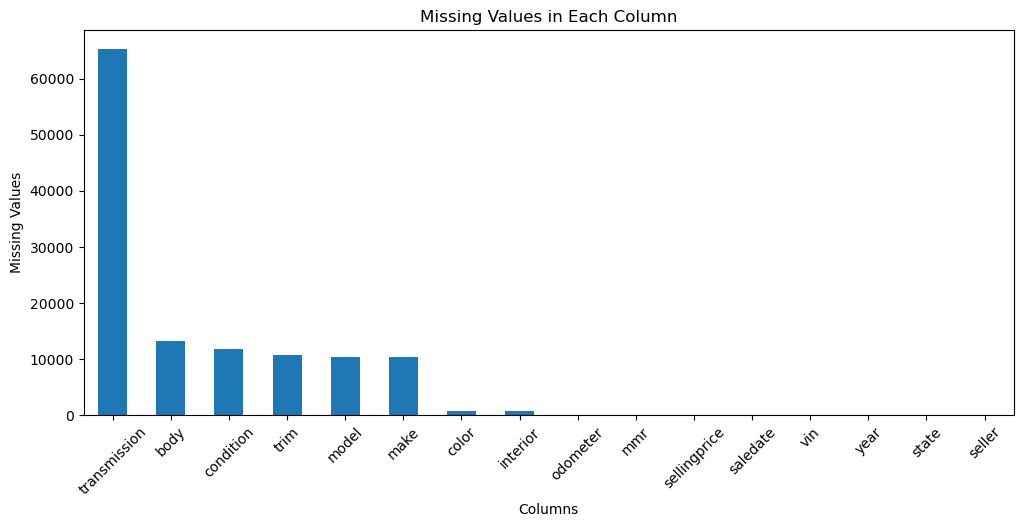

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

missing.sort_values(ascending=False).plot(kind='bar')

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)

plt.show()

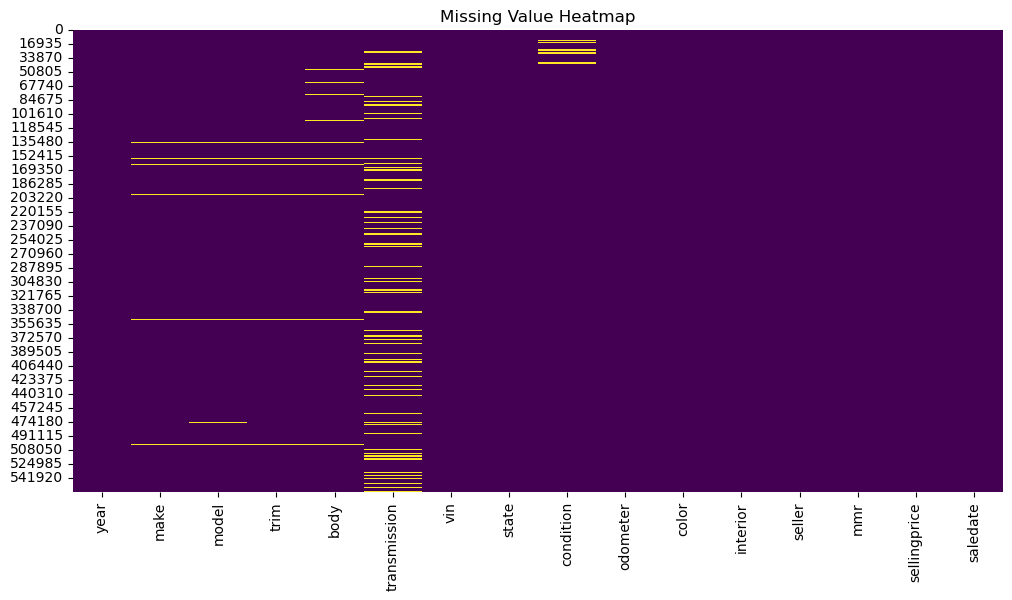

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Missing Value Heatmap")

plt.show()

In [8]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

print(num_cols)

Index(['year', 'condition', 'odometer', 'mmr', 'sellingprice'], dtype='object')


In [9]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [10]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [11]:
print(df.isnull().sum())

year                0
make            10301
model           10399
trim            10651
body            13195
transmission    65352
vin                 4
state               0
condition           0
odometer            0
color             749
interior          749
seller              0
mmr                 0
sellingprice        0
saledate           12
dtype: int64


In [12]:
duplicates = df.duplicated().sum()

print("Duplicate Records =", duplicates)

Duplicate Records = 0


In [13]:
df.drop_duplicates(inplace=True)

print("New Shape:", df.shape)

New Shape: (558837, 16)


In [14]:
print("Average Selling Price : $", round(df["sellingprice"].mean(),2))
print("Minimum Selling Price : $", df["sellingprice"].min())
print("Maximum Selling Price : $", df["sellingprice"].max())

Average Selling Price : $ 13611.33
Minimum Selling Price : $ 1.0
Maximum Selling Price : $ 230000.0


In [15]:
print("Unique Car Colors:")
print(df["color"].unique())

print("\nTotal Unique Colors:", df["color"].nunique())

Unique Car Colors:
['white' 'gray' 'black' 'red' 'silver' 'blue' 'brown' 'beige' 'purple'
 'burgundy' '—' 'gold' 'yellow' 'green' 'charcoal' nan 'orange'
 'off-white' 'turquoise' 'pink' 'lime' '4802' '9410' '1167' '2172' '14872'
 '12655' '15719' '6388' '16633' '11034' '2711' '6864' '339' '18384' '9887'
 '9837' '20379' '20627' '721' '6158' '2817' '5705' '18561' '2846' '9562'
 '5001']

Total Unique Colors: 46


In [16]:
print("Number of Unique Car Brands:", df["make"].nunique())

print("Number of Unique Car Models:", df["model"].nunique())

Number of Unique Car Brands: 96
Number of Unique Car Models: 973


In [17]:
expensive_cars = df[df["sellingprice"] > 165000]

print(expensive_cars)

# Number of such cars
print("\nTotal Cars:", len(expensive_cars))

        year           make       model      trim   body transmission  \
125095  2012    Rolls-Royce       Ghost      Base  Sedan    automatic   
344905  2014           Ford      Escape  Titanium    SUV    automatic   
446949  2015  Mercedes-Benz     S-Class   S65 AMG  Sedan    automatic   
538347  2012    Rolls-Royce       Ghost      Base  sedan    automatic   
545523  2013    Rolls-Royce       Ghost      Base  sedan    automatic   
548169  2011        Ferrari  458 Italia      Base  coupe    automatic   
557570  2012    Rolls-Royce       Ghost       EWB  sedan    automatic   

                      vin state  condition  odometer  color interior  \
125095  sca664s58cux50727    fl       45.0   14316.0  black    beige   
344905  1fmcu9j98eua23833    mo       43.0   27802.0  green      tan   
446949  wddug7kb2fa102347    ca       41.0    5277.0  white    white   
538347  sca664s59cux50803    ca       44.0    5215.0  white      tan   
545523  sca664s52dux52152    fl       42.0    7852.0  w

In [18]:
top5_models = df["model"].value_counts().head(5)

print(top5_models)

model
Altima    19349
F-150     14479
Fusion    12946
Camry     12545
Escape    11861
Name: count, dtype: int64


In [19]:
avg_price = df.groupby("make")["sellingprice"].mean().sort_values(ascending=False)

print(avg_price)

make
Rolls-Royce    153488.235294
Ferrari        127210.526316
Lamborghini    112625.000000
Bentley         74367.672414
airstream       71000.000000
                   ...      
dodge tk          550.000000
Geo               528.947368
dot               500.000000
ford truck        483.333333
Daewoo            400.000000
Name: sellingprice, Length: 96, dtype: float64


In [20]:
min_price = df.groupby("interior")["sellingprice"].min()

print(min_price)

interior
beige         100.0
black           1.0
blue          150.0
brown         200.0
burgundy      175.0
gold          250.0
gray            1.0
green         100.0
off-white     900.0
orange       1200.0
purple        200.0
red           200.0
silver        150.0
tan           100.0
white         350.0
yellow       3100.0
—             150.0
Name: sellingprice, dtype: float64


In [21]:
highest_odometer = (
    df.groupby("year")["odometer"]
      .max()
      .sort_values(ascending=False)
)

print(highest_odometer)

year
1999    999999.0
2013    999999.0
2011    999999.0
2010    999999.0
2009    999999.0
2008    999999.0
2007    999999.0
2006    999999.0
2005    999999.0
2004    999999.0
2003    999999.0
2002    999999.0
2001    999999.0
2014    999999.0
1998    999999.0
1997    999999.0
1996    999999.0
1993    999999.0
2012    999999.0
2000    462579.0
1995    396793.0
1992    379307.0
1994    356402.0
1991    274149.0
1986    273327.0
1990    265498.0
1988    241751.0
1987    230946.0
1989    218052.0
1984    170799.0
1985    121644.0
2015    100454.0
1982     85738.0
1983     42697.0
Name: odometer, dtype: float64


In [22]:
df["car_age"] = 2025 - df["year"]

print(df[["year","car_age"]].head())

   year  car_age
0  2015       10
1  2015       10
2  2014       11
3  2015       10
4  2014       11


In [23]:
cars = df[(df["condition"] >= 48) &
          (df["odometer"] > 90000)]

print("Number of Cars:", len(cars))

Number of Cars: 746


In [24]:
new_cars = df[df["year"] > 2013]

state_price = (
    new_cars.groupby("state")["sellingprice"]
    .mean()
    .sort_values(ascending=False)
)

print(state_price)

print("\nTop 5 States:")
print(state_price.head())

state
oh                   28020.221053
ab                   25204.255319
nj                   24237.063973
on                   22962.560386
qc                   22722.938144
                         ...     
3vwd17aj5fm225953    13200.000000
3vwd17aj8fm239622    13200.000000
3vwd17aj4fm201708    13200.000000
3vwd17aj3fm276741    13200.000000
ok                   10600.000000
Name: sellingprice, Length: 64, dtype: float64

Top 5 States:
state
oh    28020.221053
ab    25204.255319
nj    24237.063973
on    22962.560386
qc    22722.938144
Name: sellingprice, dtype: float64


In [25]:
threshold = df["condition"].quantile(0.80)

excellent_cars = df[df["condition"] >= threshold]

value_for_money = (
    excellent_cars.groupby("make")["sellingprice"]
    .mean()
    .sort_values()
)

print(value_for_money)

print("\nTop 10 Value for Money Brands:")
print(value_for_money.head(10))

make
Isuzu            1125.000000
Oldsmobile       1910.000000
honda            4233.333333
Saturn           5700.406504
subaru           6200.000000
                   ...      
Tesla           66580.000000
Bentley         96040.000000
Lamborghini    113000.000000
Ferrari        137888.888889
Rolls-Royce    152714.285714
Name: sellingprice, Length: 76, dtype: float64

Top 10 Value for Money Brands:
make
Isuzu         1125.000000
Oldsmobile    1910.000000
honda         4233.333333
Saturn        5700.406504
subaru        6200.000000
chrysler      6225.000000
smart         6835.759494
mazda         7275.000000
Pontiac       7686.824324
Saab          7711.111111
Name: sellingprice, dtype: float64


                  year  condition  odometer       mmr  sellingprice   car_age
year          1.000000   0.323564 -0.772415  0.596594      0.586474 -1.000000
condition     0.323564   1.000000 -0.304580  0.273153      0.313120 -0.323564
odometer     -0.772415  -0.304580  1.000000 -0.587958     -0.582267  0.772415
mmr           0.596594   0.273153 -0.587958  1.000000      0.983634 -0.596594
sellingprice  0.586474   0.313120 -0.582267  0.983634      1.000000 -0.586474
car_age      -1.000000  -0.323564  0.772415 -0.596594     -0.586474  1.000000


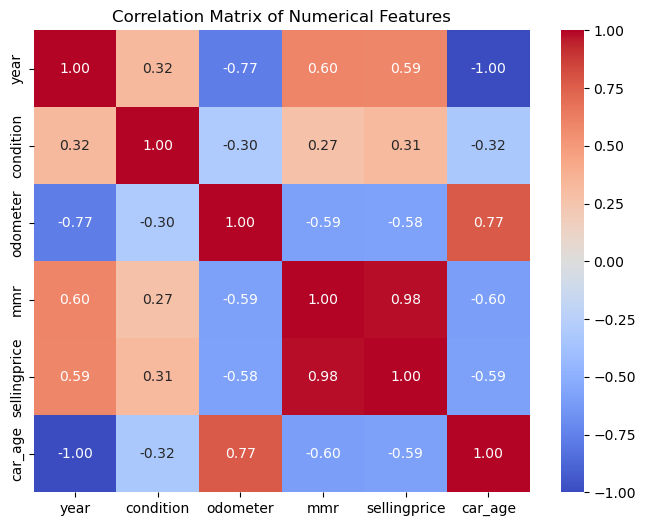

In [26]:
# Select numerical columns
num_df = df.select_dtypes(include=['int64', 'float64'])

# Correlation matrix
corr = num_df.corr()

print(corr)

# Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [27]:
# Insight
# Selling price is generally positively correlated with MMR.
# Selling price is negatively correlated with car age/odometer.
# Odometer generally increases as vehicle age increases.

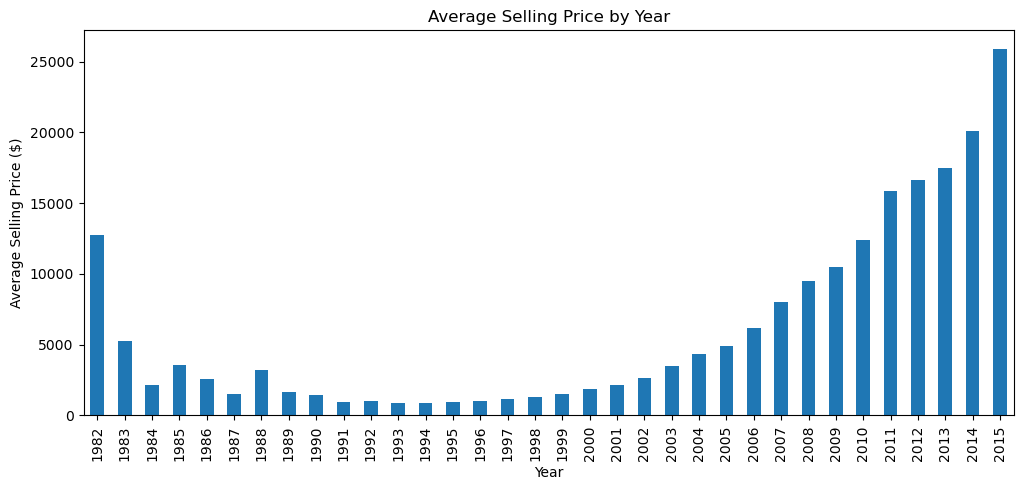

In [28]:
avg_price_year = df.groupby("year")["sellingprice"].mean()

plt.figure(figsize=(12,5))
avg_price_year.plot(kind='bar')

plt.title("Average Selling Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Selling Price ($)")
plt.show()

In [29]:
# Insight
# Newer cars have a higher average selling price.
# Older cars generally sell for lower prices because of depreciation.

C:\Users\HP\AppData\Local\Temp\ipykernel_11496\375522737.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_price_odometer = df.groupby(odometer_bins)["sellingprice"].mean()


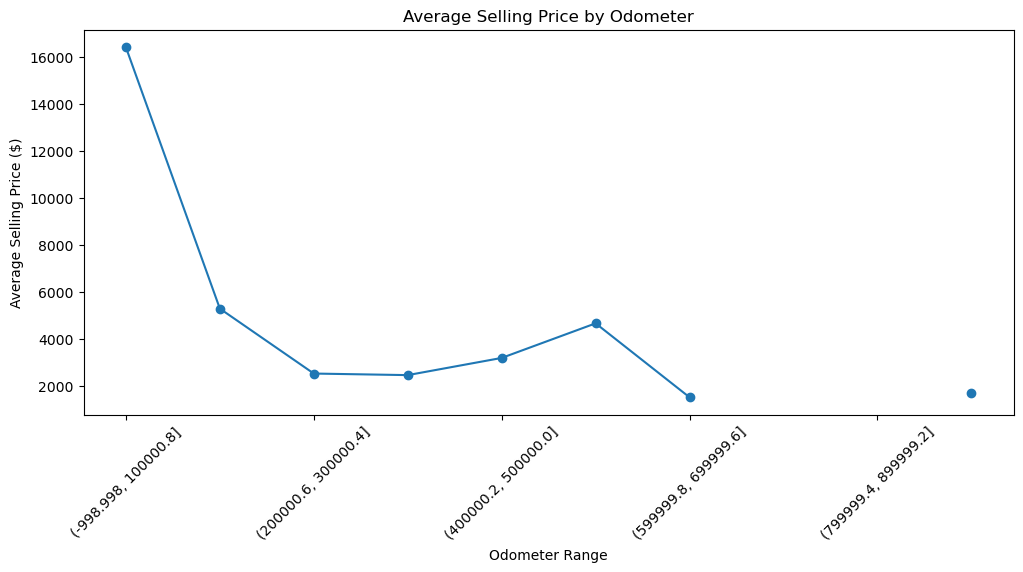

In [30]:
odometer_bins = pd.cut(df["odometer"], bins=10)

avg_price_odometer = df.groupby(odometer_bins)["sellingprice"].mean()

plt.figure(figsize=(12,5))
avg_price_odometer.plot(marker='o')

plt.title("Average Selling Price by Odometer")
plt.xlabel("Odometer Range")
plt.ylabel("Average Selling Price ($)")
plt.xticks(rotation=45)
plt.show()

In [31]:
# Insight
# Cars with lower mileage have higher selling prices.
# Selling price decreases as odometer reading increases.

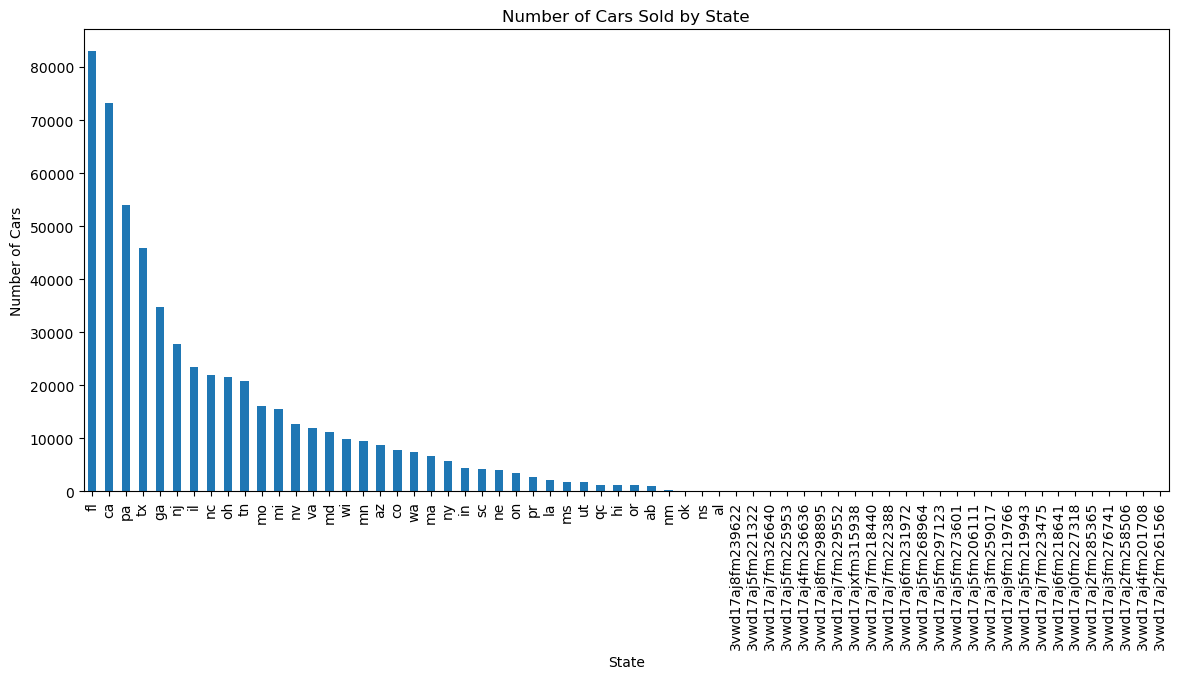

Top 3 States:
state
fl    82945
ca    73148
pa    53907
Name: count, dtype: int64


In [32]:
state_sales = df["state"].value_counts()

plt.figure(figsize=(14,6))
state_sales.plot(kind='bar')

plt.title("Number of Cars Sold by State")
plt.xlabel("State")
plt.ylabel("Number of Cars")
plt.show()

print("Top 3 States:")
print(state_sales.head(3))

In [33]:
#Insight
# The graph will show the top three states with the highest number of cars sold.

C:\Users\HP\AppData\Local\Temp\ipykernel_11496\1987311011.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_condition = df.groupby("Condition_Range")["sellingprice"].mean()


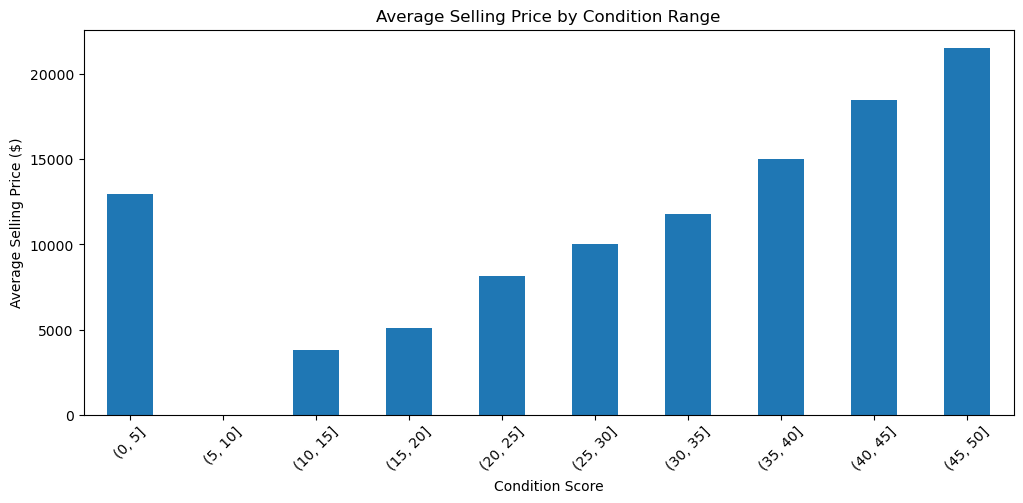

In [36]:
condition_bins = range(0, 55, 5)

df["Condition_Range"] = pd.cut(df["condition"], bins=condition_bins)

avg_condition = df.groupby("Condition_Range")["sellingprice"].mean()

plt.figure(figsize=(12,5))
avg_condition.plot(kind='bar')

plt.title("Average Selling Price by Condition Range")
plt.xlabel("Condition Score")
plt.ylabel("Average Selling Price ($)")
plt.xticks(rotation=45)
plt.show()

In [37]:
# Insights
# Higher condition scores generally result in higher selling prices.
# Cars in excellent condition command premium prices.

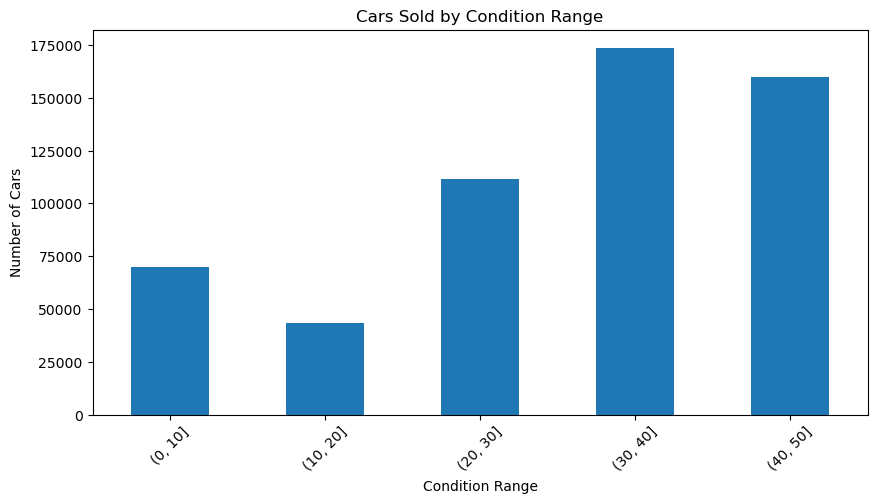

In [38]:
condition_bins = range(0, 60, 10)

df["Condition_Group"] = pd.cut(df["condition"], bins=condition_bins)

condition_count = df["Condition_Group"].value_counts().sort_index()

plt.figure(figsize=(10,5))
condition_count.plot(kind='bar')

plt.title("Cars Sold by Condition Range")
plt.xlabel("Condition Range")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

In [39]:
# Insights
# Most cars are concentrated in the middle condition ranges.
# Very low and very high condition scores have fewer listings.

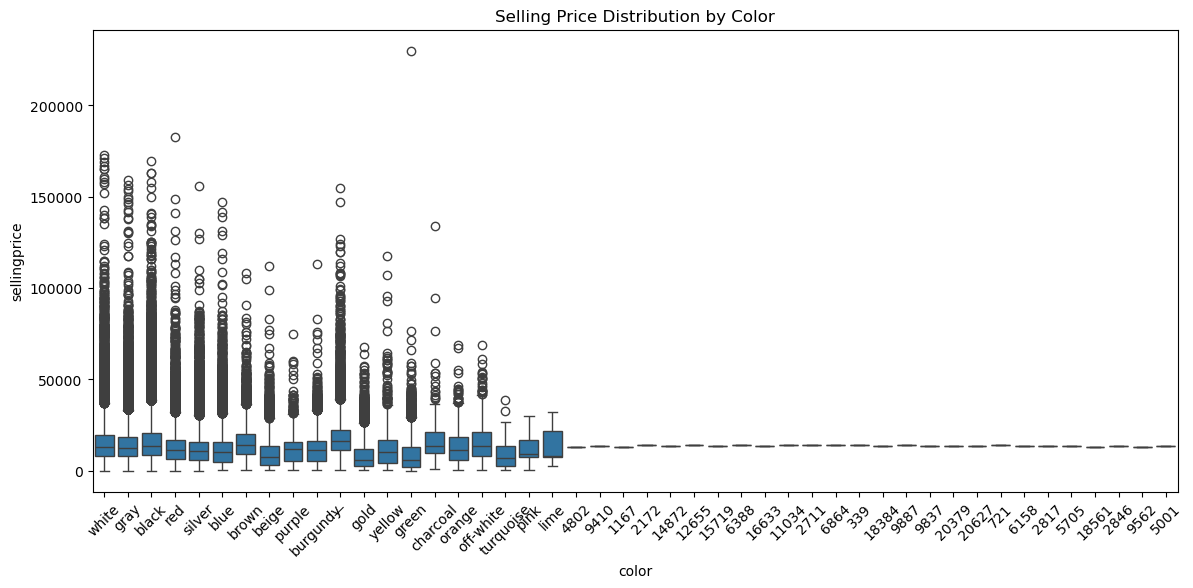

In [40]:
plt.figure(figsize=(14,6))

sns.boxplot(
    x="color",
    y="sellingprice",
    data=df
)

plt.xticks(rotation=45)
plt.title("Selling Price Distribution by Color")
plt.show()

In [41]:
Q1 = df["sellingprice"].quantile(0.25)
Q3 = df["sellingprice"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["sellingprice"] >= lower) &
    (df["sellingprice"] <= upper)
]

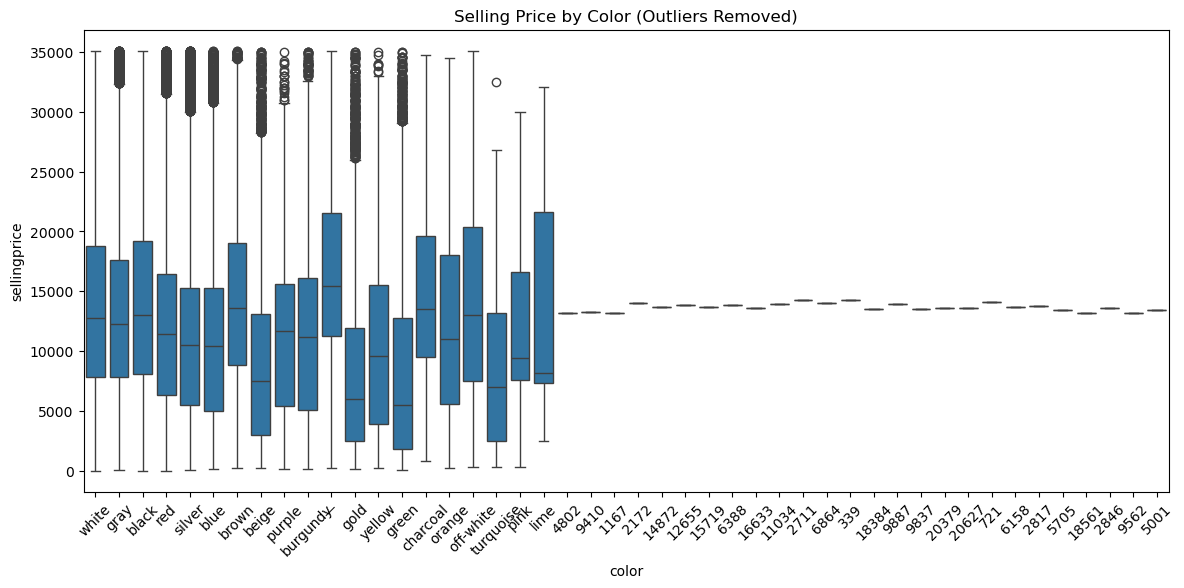

In [42]:
plt.figure(figsize=(14,6))

sns.boxplot(
    x="color",
    y="sellingprice",
    data=df_no_outliers
)

plt.xticks(rotation=45)
plt.title("Selling Price by Color (Outliers Removed)")
plt.show()

In [ ]:
# Insights
# The original box plot may contain many extreme price outliers.
# After removing outliers, the price distribution becomes more compact and easier to compare across colors.
# Car color has much less influence on price than factors such as year, condition, and odometer.